# M Dim Ablation

This notebook compares M embedding dimensions using averaged multi-seed linear query projection runs.

## Setup

The notebook reads the grouped experiment result from `output/summary.json`.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

OUTPUT_DIR = Path("output")
SUMMARY_PATH = OUTPUT_DIR / "summary.json"

plt.rcParams.update(
    {
        "figure.dpi": 150,
        "savefig.dpi": 300,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.edgecolor": "#D1D5DB",
        "axes.labelcolor": "#111827",
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "xtick.color": "#374151",
        "ytick.color": "#374151",
        "grid.color": "#E5E7EB",
        "grid.linewidth": 0.8,
        "legend.frameon": False,
        "font.size": 10,
    }
)

SPLIT_COLORS = {
    "dev": "#2563EB",
    "test": "#059669",
    "xeval": "#D97706",
}


## Load Results

The aggregate table contains one averaged row per M dimension.

In [2]:
with SUMMARY_PATH.open("r", encoding="utf-8") as file:
    summary = json.load(file)

runs = summary["runs"]
aggregates = summary["aggregate"]


def flatten_aggregate(item: dict) -> dict:
    row = {
        "m_dim": item["m_dim"],
        "num_seeds": item["num_seeds"],
        "best_epoch": item["best_epoch"],
    }

    for split_name in ("best_dev", "test", "xeval"):
        for metric_name in ("loss", "top1", "ndcg"):
            row[f"{split_name}_{metric_name}"] = item[split_name][metric_name]

    return row


aggregate_df = pd.DataFrame([flatten_aggregate(item) for item in aggregates])
aggregate_df = aggregate_df.sort_values("m_dim").reset_index(drop=True)

display(aggregate_df)


,m_dim,num_seeds,best_epoch,best_dev_loss,best_dev_top1,best_dev_ndcg,test_loss,test_top1,test_ndcg,xeval_loss,xeval_top1,xeval_ndcg
0,0,5,13.8,1.595766,0.335714,0.805662,1.593271,0.192857,0.786291,1.632458,0.159829,0.709167
1,8,5,11.2,1.581402,0.428571,0.852001,1.586663,0.364286,0.824767,1.604155,0.243590,0.756589
2,16,5,8.8,1.572564,0.521429,0.864700,1.582074,0.378571,0.824571,1.586677,0.298291,0.797055
3,32,5,8.0,1.570458,0.542857,0.867552,1.581580,0.364286,0.819632,1.583021,0.318803,0.807729
4,64,5,8.4,1.563811,0.542857,0.869465,1.577881,0.371429,0.821156,1.574166,0.313248,0.816751
5,128,5,6.2,1.569090,0.571429,0.870178,1.582144,0.357143,0.816404,1.577370,0.325641,0.817335
6,256,5,4.6,1.570975,0.557143,0.870953,1.584004,0.335714,0.813070,1.579341,0.329487,0.819165


## Per-Seed Results

This table keeps the raw seed-level results available for inspection.

In [3]:
def best_epoch_from_history(run: dict) -> int:
    history = run["history"]
    best_item = max(history, key=lambda item: item["dev"]["ndcg"])
    return int(best_item["epoch"])


seed_records = []
for run in runs:
    experiment = run["experiment"]
    best_dev = run["best_dev"]
    test = run["test"]
    xeval = run["xeval"]

    seed_records.append(
        {
            "run": experiment["name"],
            "m_dim": experiment["m_embedding_dim"],
            "seed": experiment["seed"],
            "best_epoch": best_epoch_from_history(run),
            "best_dev_top1": best_dev["top1"],
            "best_dev_ndcg": best_dev["ndcg"],
            "test_top1": test["top1"],
            "test_ndcg": test["ndcg"],
            "xeval_top1": xeval["top1"],
            "xeval_ndcg": xeval["ndcg"],
        }
    )

seed_df = pd.DataFrame(seed_records).sort_values(["m_dim", "seed"]).reset_index(drop=True)
display(seed_df)


,run,m_dim,seed,best_epoch,best_dev_top1,best_dev_ndcg,test_top1,test_ndcg,xeval_top1,xeval_ndcg
0,m0,0,7,17,0.392857,0.826034,0.250000,0.784721,0.162393,0.704923
1,m0,0,13,19,0.250000,0.798473,0.142857,0.790116,0.160256,0.703940
2,m0,0,21,14,0.178571,0.791892,0.250000,0.808063,0.141026,0.705008
3,m0,0,42,2,0.464286,0.809034,0.142857,0.756133,0.188034,0.730026
4,m0,0,100,17,0.392857,0.802876,0.178571,0.792421,0.147436,0.701939
5,m8,8,7,12,0.464286,0.859580,0.428571,0.831282,0.226496,0.746736
6,m8,8,13,10,0.392857,0.840116,0.321429,0.825646,0.290598,0.779903
7,m8,8,21,9,0.357143,0.844812,0.357143,0.816599,0.262821,0.777051
8,m8,8,42,14,0.464286,0.859503,0.357143,0.827581,0.181624,0.718035
9,m8,8,100,11,0.464286,0.855993,0.357143,0.822729,0.256410,0.761220


## Metrics

Top-1 and nDCG values are shown as percentages.

In [4]:
metric_rows = []
for _, row in aggregate_df.iterrows():
    metric_rows.append(
        {
            "m_dim": int(row["m_dim"]),
            "seeds": int(row["num_seeds"]),
            "best_epoch": f"{row['best_epoch']:.1f}",
            "dev_top1": 100.0 * row["best_dev_top1"],
            "dev_ndcg": 100.0 * row["best_dev_ndcg"],
            "test_top1": 100.0 * row["test_top1"],
            "test_ndcg": 100.0 * row["test_ndcg"],
            "xeval_top1": 100.0 * row["xeval_top1"],
            "xeval_ndcg": 100.0 * row["xeval_ndcg"],
        }
    )

metrics_df = pd.DataFrame(metric_rows)
display(
    metrics_df.style.format(
        {
            "dev_top1": "{:.2f}",
            "dev_ndcg": "{:.2f}",
            "test_top1": "{:.2f}",
            "test_ndcg": "{:.2f}",
            "xeval_top1": "{:.2f}",
            "xeval_ndcg": "{:.2f}",
        }
    )
    .background_gradient(subset=["dev_ndcg", "test_ndcg", "xeval_ndcg"], cmap="Blues")
    .background_gradient(subset=["dev_top1", "test_top1", "xeval_top1"], cmap="Greens")
)


,m_dim,seeds,best_epoch,dev_top1,dev_ndcg,test_top1,test_ndcg,xeval_top1,xeval_ndcg
0,0,5,13.8,33.57,80.57,19.29,78.63,15.98,70.92
1,8,5,11.2,42.86,85.20,36.43,82.48,24.36,75.66
2,16,5,8.8,52.14,86.47,37.86,82.46,29.83,79.71
3,32,5,8.0,54.29,86.76,36.43,81.96,31.88,80.77
4,64,5,8.4,54.29,86.95,37.14,82.12,31.32,81.68
5,128,5,6.2,57.14,87.02,35.71,81.64,32.56,81.73
6,256,5,4.6,55.71,87.10,33.57,81.31,32.95,81.92


## Best Setting

The selected setting is the highest averaged dev nDCG, with averaged dev Top-1 as the secondary signal.

In [5]:
best = aggregate_df.sort_values(
    ["best_dev_ndcg", "best_dev_top1", "m_dim"],
    ascending=[False, False, True],
).iloc[0]

print(f"best M dim: {int(best.m_dim)}")
print(f"seeds: {int(best.num_seeds)}")
print(f"best epoch: {best.best_epoch:.1f}")
print(f"dev top1: {best.best_dev_top1:.4f}")
print(f"dev ndcg: {best.best_dev_ndcg:.4f}")
print(f"test top1: {best.test_top1:.4f}")
print(f"test ndcg: {best.test_ndcg:.4f}")
print(f"xeval top1: {best.xeval_top1:.4f}")
print(f"xeval ndcg: {best.xeval_ndcg:.4f}")


best M dim: 256
seeds: 5
best epoch: 4.6
dev top1: 0.5571
dev ndcg: 0.8710
test top1: 0.3357
test ndcg: 0.8131
xeval top1: 0.3295
xeval ndcg: 0.8192


## Delta

Each M dimension is compared against the no-M baseline `m0`.

In [6]:
baseline = aggregate_df[aggregate_df["m_dim"] == 0].iloc[0]

delta = aggregate_df[["m_dim"]].copy()
for col in [
    "best_dev_top1",
    "best_dev_ndcg",
    "test_top1",
    "test_ndcg",
    "xeval_top1",
    "xeval_ndcg",
]:
    delta[col + "_delta"] = 100.0 * (aggregate_df[col] - baseline[col])

display(
    delta.style.format({col: "{:+.2f}" for col in delta.columns if col != "m_dim"})
    .background_gradient(
        subset=[col for col in delta.columns if col != "m_dim"],
        cmap="RdYlGn",
        axis=0,
    )
)


,m_dim,best_dev_top1_delta,best_dev_ndcg_delta,test_top1_delta,test_ndcg_delta,xeval_top1_delta,xeval_ndcg_delta
0,0,+0.00,+0.00,+0.00,+0.00,+0.00,+0.00
1,8,+9.29,+4.63,+17.14,+3.85,+8.38,+4.74
2,16,+18.57,+5.90,+18.57,+3.83,+13.85,+8.79
3,32,+20.71,+6.19,+17.14,+3.33,+15.90,+9.86
4,64,+20.71,+6.38,+17.86,+3.49,+15.34,+10.76
5,128,+23.57,+6.45,+16.43,+3.01,+16.58,+10.82
6,256,+22.14,+6.53,+14.29,+2.68,+16.97,+11.00


## Split Plots

Bar charts show averaged performance for each M dimension.

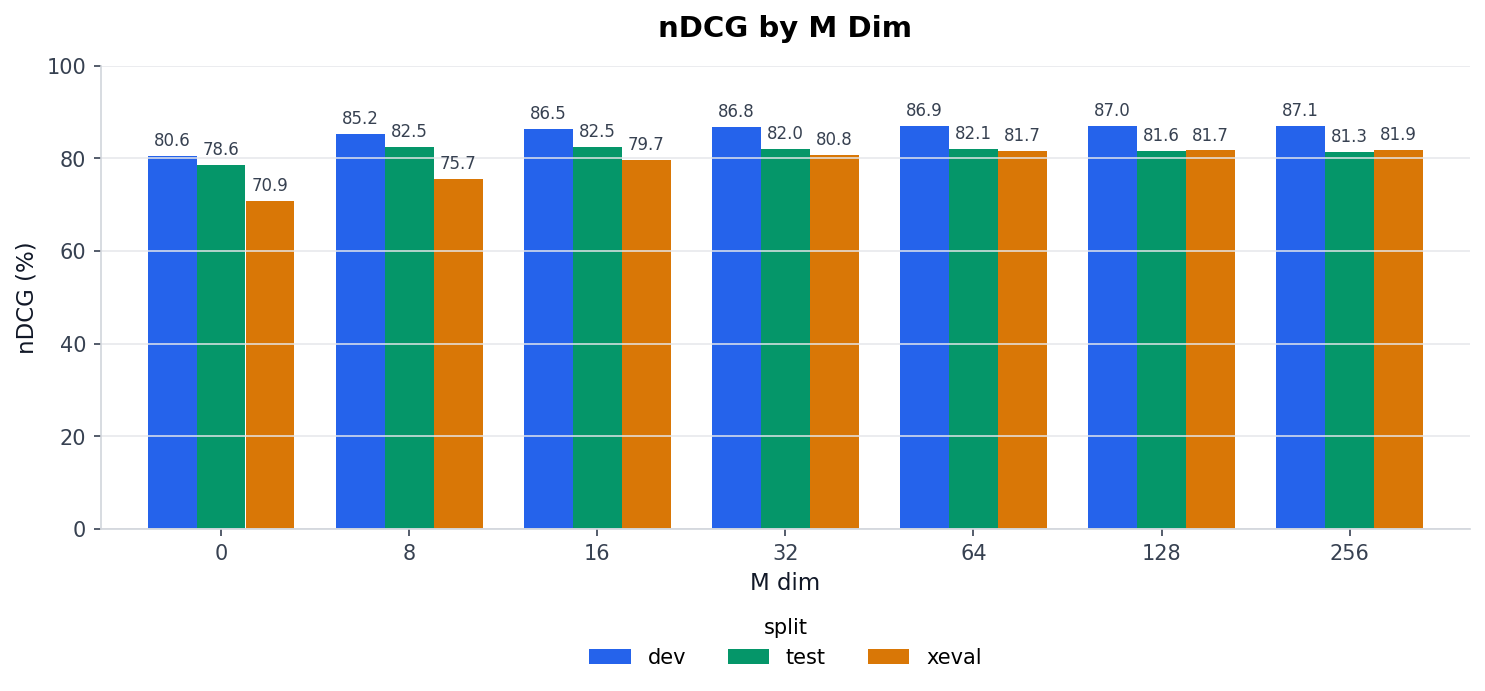

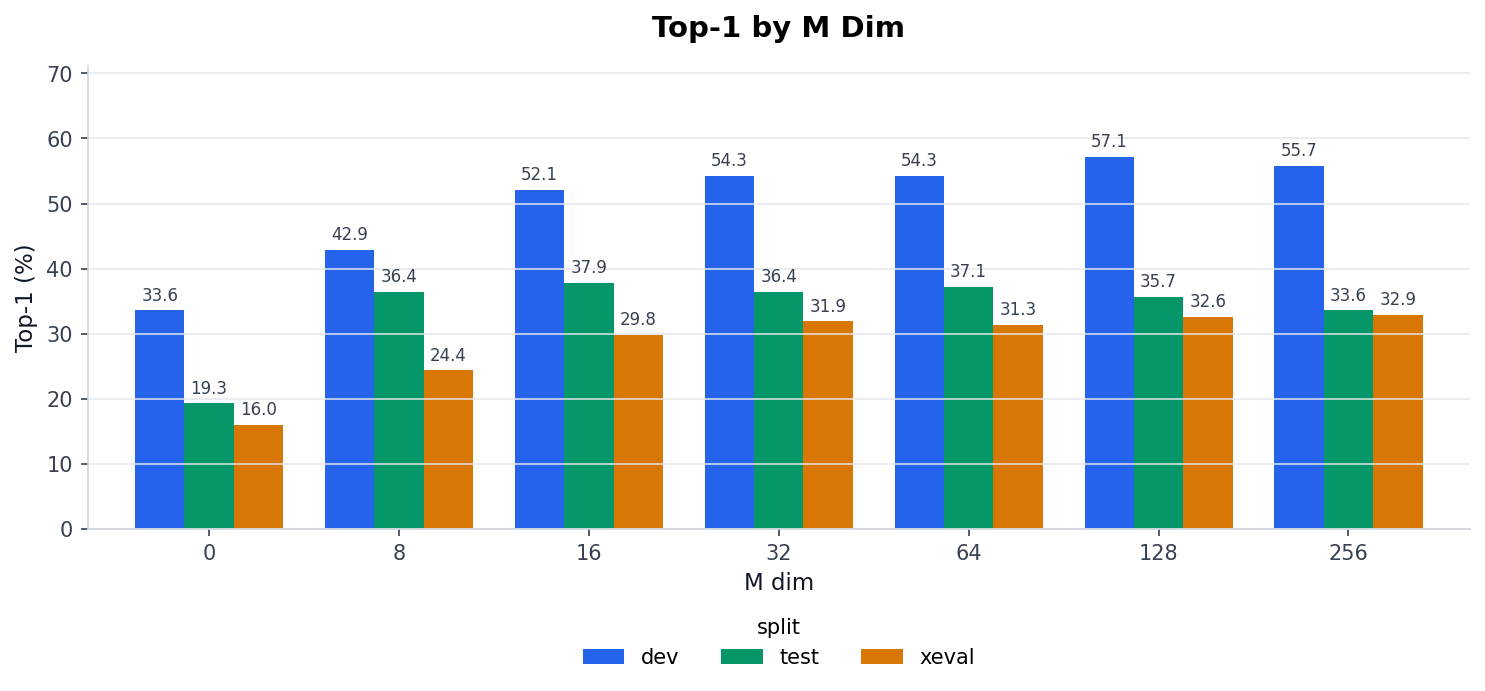

In [7]:
def finish_axis(ax, ylabel: str) -> None:
    ax.set_xlabel("M dim")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#D1D5DB")
    ax.spines["bottom"].set_color("#D1D5DB")
    ax.legend(title="split", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)


def plot_metric(metric_name: str, title: str, ylabel: str) -> None:
    plot_df = aggregate_df[["m_dim", f"best_dev_{metric_name}", f"test_{metric_name}", f"xeval_{metric_name}"]].copy()
    plot_df = plot_df.rename(
        columns={
            f"best_dev_{metric_name}": "dev",
            f"test_{metric_name}": "test",
            f"xeval_{metric_name}": "xeval",
        }
    )
    plot_df[["dev", "test", "xeval"]] = plot_df[["dev", "test", "xeval"]] * 100.0

    ax = plot_df.set_index("m_dim")[["dev", "test", "xeval"]].plot(
        kind="bar",
        figsize=(10, 4.8),
        rot=0,
        width=0.78,
        color=[SPLIT_COLORS["dev"], SPLIT_COLORS["test"], SPLIT_COLORS["xeval"]],
    )

    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f", padding=3, fontsize=8, color="#374151")

    ax.set_title(title, pad=14)
    upper = float(plot_df[["dev", "test", "xeval"]].to_numpy().max())
    ax.set_ylim(0, min(100, upper + 14))
    finish_axis(ax, ylabel)
    plt.tight_layout()
    plt.show()


plot_metric("ndcg", "nDCG by M Dim", "nDCG (%)")
plot_metric("top1", "Top-1 by M Dim", "Top-1 (%)")
